In [1]:
!pip install qiskit qiskit_aer

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.8/9.8 MB 37.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 55.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 36.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.9/54.9 kB 3.0 MB/s eta 0:00:00


In [49]:
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram

backend = AerSimulator()
SHOTS = 1024

### Porte Z multi-contrôlée
La diffusion et l'oracle ont tous deux besoin d'une inversion de phase conditionnelle sur $|1\dots1\rangle$ : CZ pour 2 qubits, CCZ pour 3 qubits, etc. On la construit de façon générique avec l'identité $Z = HXH$ : une Toffoli généralisée (MCX) entourée de deux portes $H$ sur le qubit cible.

In [50]:
def mcz(qc, qubits):
    if len(qubits) == 1:
        qc.z(qubits[0])
    elif len(qubits) == 2:
        qc.cz(qubits[0], qubits[1])
    else:
        target = qubits[-1]
        qc.h(target)
        qc.mcx(qubits[:-1], target)
        qc.h(target)

### Oracle dynamique $O_f$

L'oracle doit inverser la phase. C'est un phase kickback

In [51]:
def oracle(target):
    n = len(target)
    qc = QuantumCircuit(n)
    zeros = [i for i, bit in enumerate(target[::-1]) if bit == "0"]
    if zeros:
        qc.x(zeros)
    mcz(qc, list(range(n)))
    if zeros:
        qc.x(zeros)
    return qc

oracle("10").draw()

┌───┐   ┌───┐
q_0: ┤ X ├─■─┤ X ├
     └───┘ │ └───┘
q_1: ──────■──────

### Opérateur de diffusion $D$

Implémentation selon l'énoncé : (a) $H$ partout, (b) $X$ partout, (c) Z multi-contrôlée, (d) $X$ partout, (e) $H$ partout.

Les étapes (b)-(c)-(d) inversent la phase de $|0\dots0\rangle$, ce qui réalise $I - 2|0\rangle\langle 0|$. Entouré des $H$, on obtient $I - 2|\psi_0\rangle\langle\psi_0| = -D$ : c'est $D$ à une phase globale $-1$ près, sans effet sur les probabilités de mesure.

In [52]:
def diffuser(n):
    qc = QuantumCircuit(n)
    qc.h(range(n))
    qc.x(range(n))
    mcz(qc, list(range(n)))
    qc.x(range(n))
    qc.h(range(n))
    return qc

diffuser(2).draw()

┌───┐┌───┐   ┌───┐┌───┐
q_0: ┤ H ├┤ X ├─■─┤ X ├┤ H ├
     ├───┤├───┤ │ ├───┤├───┤
q_1: ┤ H ├┤ X ├─■─┤ X ├┤ H ├
     └───┘└───┘   └───┘└───┘

### Circuit de Grover

Initialisation $H^{\otimes n}$, puis $r$ itérations $G = D \cdot O_f$, puis mesure. Le nombre de qubits est déduit de la longueur de la cible.

In [ ]:
def grover(target, r=1):
    n = len(target)
    qc = QuantumCircuit(n, n)
    qc.h(range(n))
    O, D = oracle(target), diffuser(n)
    for _ in range(r):
        qc.compose(O, inplace=True)    # oracle
        qc.compose(D, inplace=True)    # diffusion
    qc.measure(range(n), range(n))     # mesure
    return qc

def run(qc, shots=SHOTS):
    return backend.run(transpile(qc, backend), shots=shots).result().get_counts()

def p_theory(r, N): #fonction pour vérifier les valeurs empiriques et théoriques
    theta = 2 * np.arcsin(1 / np.sqrt(N))
    return np.sin((r + 0.5) * theta) ** 2

---
# Partie 1 — Grover sur 2 qubits, une seule itération

In [54]:
target = "10"
qc2 = grover(target, r=1)
qc2.draw()

┌───┐┌───┐   ┌───┐┌───┐┌───┐   ┌───┐┌───┐┌─┐   
q_0: ┤ H ├┤ X ├─■─┤ X ├┤ H ├┤ X ├─■─┤ X ├┤ H ├┤M├───
     ├───┤└───┘ │ ├───┤├───┤└───┘ │ ├───┤├───┤└╥┘┌─┐
q_1: ┤ H ├──────■─┤ H ├┤ X ├──────■─┤ X ├┤ H ├─╫─┤M├
     └───┘        └───┘└───┘        └───┘└───┘ ║ └╥┘
c: 2/══════════════════════════════════════════╩══╩═
                                               0  1

In [55]:
qc2.decompose().draw()

┌────────────┐┌──────────┐     ┌──────────┐┌────────────┐┌──────────┐     »
q_0: ┤ U(π/2,0,π) ├┤ U(π,0,π) ├──■──┤ U(π,0,π) ├┤ U(π/2,0,π) ├┤ U(π,0,π) ├─────»
     ├────────────┤└──┬───┬───┘┌─┴─┐└──┬───┬───┘├────────────┤├──────────┤┌───┐»
q_1: ┤ U(π/2,0,π) ├───┤ H ├────┤ X ├───┤ H ├────┤ U(π/2,0,π) ├┤ U(π,0,π) ├┤ H ├»
     └────────────┘   └───┘    └───┘   └───┘    └────────────┘└──────────┘└───┘»
c: 2/══════════════════════════════════════════════════════════════════════════»
                                                                               »
«          ┌──────────┐┌────────────┐              ┌─┐   
«q_0: ──■──┤ U(π,0,π) ├┤ U(π/2,0,π) ├──────────────┤M├───
«     ┌─┴─┐└──┬───┬───┘└┬──────────┬┘┌────────────┐└╥┘┌─┐
«q_1: ┤ X ├───┤ H ├─────┤ U(π,0,π) ├─┤ U(π/2,0,π) ├─╫─┤M├
«     └───┘   └───┘     └──────────┘ └────────────┘ ║ └╥┘
«c: 2/══════════════════════════════════════════════╩══╩═
«                                                   0  1

{'10': 1024}


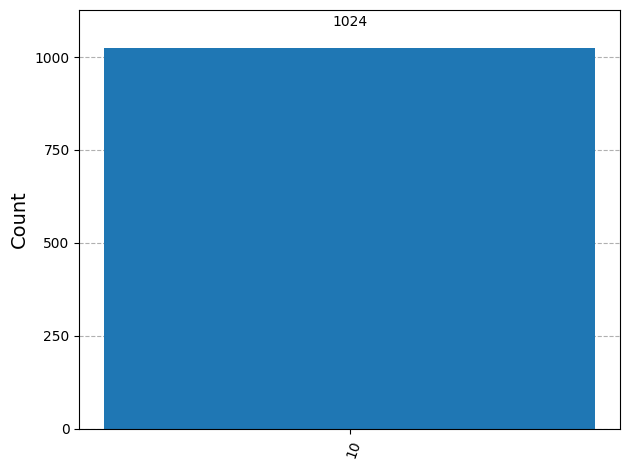

In [56]:
counts = run(qc2)
print(counts)
plot_histogram(counts)

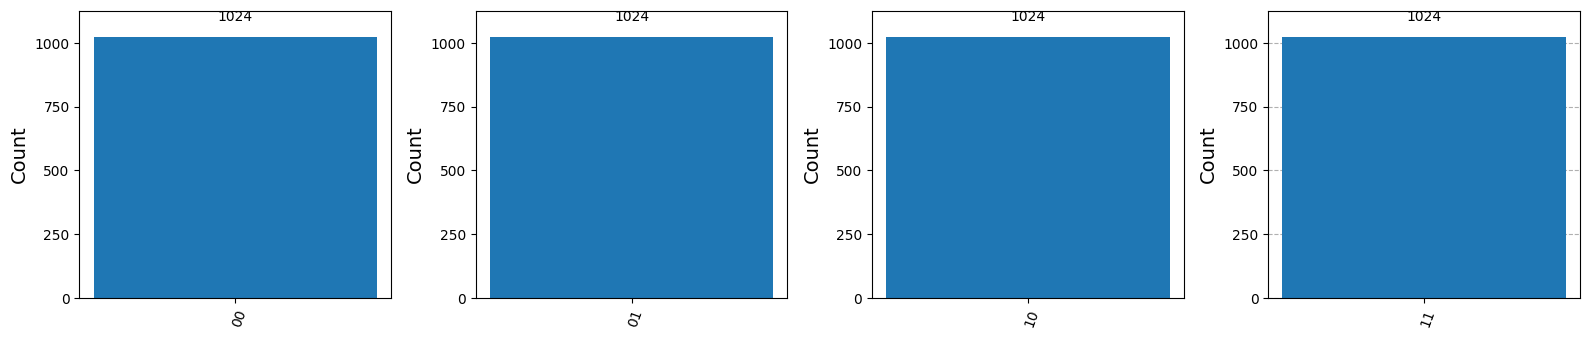

In [57]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for ax, t in zip(axes, ["00", "01", "10", "11"]):
    plot_histogram(run(grover(t, 1)), ax=ax)
plt.tight_layout()
plt.show()

### Questions

La distribution n'est pas uniforme: on obtient la cible dans 100 % des tirs, les trois autres états n'apparaissent jamais. Le résultat est identique pour les 4 cibles, ce qui confirme que l'oracle s'adapte correctement au paramètre.

L'état correct apparaît plus souvent, c'est même le seul état mesuré. Ce n'est pas un effet statistique: pour $N = 4$, $\theta = 2\arcsin(1/2) = \pi/3$, donc après une itération $p(x^*) = \sin^2(3\pi/6) = \sin^2(\pi/2) = 1$ exactement.

Pour $N = 4$, une seule itération est exactement optimale. Une requête à l'oracle suffit, contre 3 dans le pire cas classique (2,25 en moyenne). C'est un cas particulier: pour $N$ plus grand, une seule itération ne suffit plus à amplifier la cible jusqu'à une probabilité proche de 1.

---
# Partie 2 — Grover sur 3 qubits, $r$ itérations

In [58]:
target = "101"
grover(target, r=2).draw()

┌───┐          ┌───┐┌───┐               ┌───┐┌───┐               ┌───┐»
q_0: ┤ H ├───────■──┤ H ├┤ X ├────────────■──┤ X ├┤ H ├────────────■──┤ H ├»
     ├───┤┌───┐  │  ├───┤├───┤┌───┐       │  ├───┤├───┤┌───┐       │  ├───┤»
q_1: ┤ H ├┤ X ├──■──┤ X ├┤ H ├┤ X ├───────■──┤ X ├┤ H ├┤ X ├───────■──┤ X ├»
     ├───┤├───┤┌─┴─┐├───┤├───┤├───┤┌───┐┌─┴─┐├───┤├───┤├───┤┌───┐┌─┴─┐├───┤»
q_2: ┤ H ├┤ H ├┤ X ├┤ H ├┤ H ├┤ X ├┤ H ├┤ X ├┤ H ├┤ X ├┤ H ├┤ H ├┤ X ├┤ H ├»
     └───┘└───┘└───┘└───┘└───┘└───┘└───┘└───┘└───┘└───┘└───┘└───┘└───┘└───┘»
c: 3/══════════════════════════════════════════════════════════════════════»
                                                                           »
«     ┌───┐               ┌───┐┌───┐     ┌─┐      
«q_0: ┤ X ├────────────■──┤ X ├┤ H ├─────┤M├──────
«     ├───┤┌───┐       │  ├───┤├───┤     └╥┘┌─┐   
«q_1: ┤ H ├┤ X ├───────■──┤ X ├┤ H ├──────╫─┤M├───
«     ├───┤├───┤┌───┐┌─┴─┐├───┤├───┤┌───┐ ║ └╥┘┌─┐
«q_2: ┤ H ├┤ X ├┤ H ├┤ X ├┤ H ├┤ X ├┤ H ├─╫──╫─┤M├
«     └───┘└───┘└───┘└───┘└───┘└───┘└───┘ ║  ║ └╥┘
«c: 3/════════════════════════════════════╩══╩══╩═
«                                         0  1  2

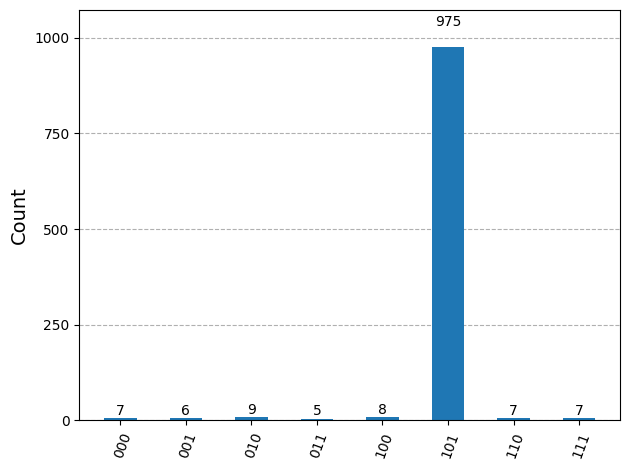

In [59]:
counts = run(grover(target, r=2))
plot_histogram(counts)

Pour chaque r, on exécute 1024 tirs et on relève la fréquence empirique de la cible, qu'on compare à la formule théorique.

In [60]:
N = 2 ** len(target)
r_values = np.arange(1, 21)

p_emp = []
for r in r_values:
    counts = run(grover(target, r))
    p_emp.append(counts.get(target, 0) / SHOTS)
p_emp = np.array(p_emp)
p_th = p_theory(r_values, N)

print(f"{'r':>3} {'empirique':>10} {'théorie':>9} {'écart':>7}")
for r, e, t in zip(r_values, p_emp, p_th):
    print(f"{r:>3} {e:>10.4f} {t:>9.4f} {abs(e-t):>7.4f}")

  r  empirique   théorie   écart
  1     0.7637    0.7812  0.0176
  2     0.9404    0.9453  0.0049
  3     0.3340    0.3301  0.0039
  4     0.0137    0.0122  0.0015
  5     0.5850    0.5480  0.0370
  6     1.0000    0.9998  0.0002
  7     0.5654    0.5770  0.0115
  8     0.0137    0.0195  0.0058
  9     0.3018    0.3029  0.0011
 10     0.9150    0.9313  0.0162
 11     0.8311    0.8049  0.0261
 12     0.1543    0.1450  0.0093
 13     0.0977    0.1063  0.0087
 14     0.7627    0.7566  0.0061
 15     0.9570    0.9578  0.0008
 16     0.3535    0.3578  0.0043
 17     0.0088    0.0066  0.0022
 18     0.5420    0.5188  0.0232
 19     0.9990    0.9981  0.0009
 20     0.6553    0.6057  0.0496


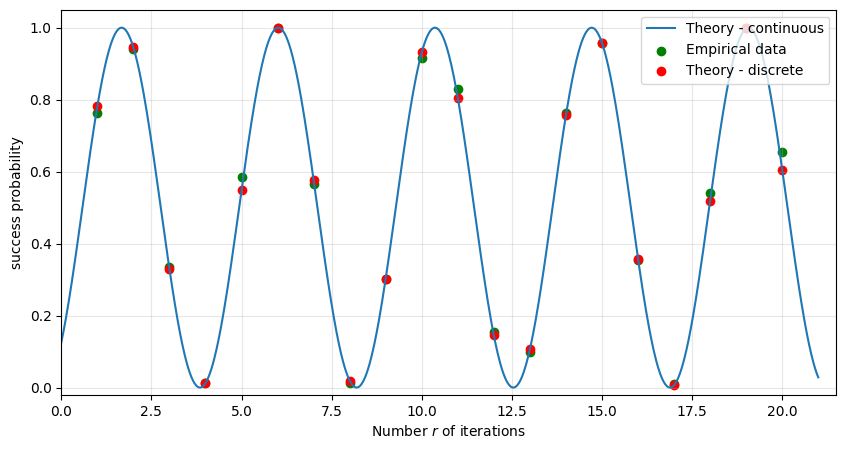

In [61]:
r_cont = np.linspace(0, 21, 1000)

plt.figure(figsize=(10, 5))
plt.plot(r_cont, p_theory(r_cont, N), label="Theory - continuous")
plt.scatter(r_values, p_emp, color="green", label="Empirical data")
plt.scatter(r_values, p_th, color="red", label="Theory - discrete")
plt.xlabel("Number $r$ of iterations")
plt.ylabel("success probability")
plt.xlim(0, 21.5)
plt.ylim(-0.02, 1.05)
plt.legend(loc="upper right")
plt.grid(alpha=0.3)
plt.show()

In [62]:
theta = 2 * np.arcsin(1 / np.sqrt(N))
r_max_cont = (np.pi / 2) / theta - 0.5          # (r + 1/2) theta = pi/2
period = np.pi / theta
r_opt = int(np.floor(np.pi / 4 * np.sqrt(N)))

print(f"theta                        = {theta:.4f} rad")
print(f"1er maximum (r continu)      = {r_max_cont:.3f}")
print(f"Période des oscillations     = {period:.3f} itérations")
print(f"r optimal floor(pi/4 sqrt N) = {r_opt}  ->  p théorique = {p_theory(r_opt, N):.4f}")

theta                        = 0.7227 rad
1er maximum (r continu)      = 1.673
Période des oscillations     = 4.347 itérations
r optimal floor(pi/4 sqrt N) = 2  ->  p théorique = 0.9453


### Questions

 Les points empiriques se superposent aux points théoriques à quelques centièmes près.

Effet de l'augmentation de r: La probabilité de succès n'augmente pas de façon monotone avec r. Chaque itération $G$ est une rotation d'angle $\theta$ dans le plan engendré par $|x^*\rangle$ et la superposition des états non marqués. Partant d'un angle $\theta/2$, l'état atteint $(r + \tfrac12)\theta$ après r itérations. Une fois la target atteinte, les itérations suivantes font dépasser la cible et la probabilité redescend jusqu'à presque 0, puis remonte, et ainsi de suite. La période vaut $\pi/\theta. Il faut estimerle nombre de solutions pour choisir r. Au risque de trop ittérer ou pas assez.

Le premier maximum de la courbe continue est en $r \approx 1{,}67$, solution de $(r + \tfrac12)\theta = \tfrac{\pi}{2}$. Comme $r$ doit être entier, on retient $r = 2$, avec $p(x^*) \approx 0{,}945$, ce que confirment les mesures. Contrairement au cas $N = 4$, on n'atteint pas exactement 1 car le maximum continu ne tombe pas sur un entier. Classiquement, il faudrait en moyenne $\approx N/2 = 4$ requêtes. Le gain reste modeste pour $N = 8$, mais l'écart $O(\sqrt{N})$ contre $O(N)$ se creuse rapidement quand $N$ grandit.

On remarque aussi que certains $r$ plus grands (par exemple r = 6) donnent une probabilité encore plus proche de 1, mais pour un coût en requêtes 3 fois supérieur.